In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42
ROOT = Path.cwd() if (Path.cwd() / "notebooks").exists() else Path.cwd().parent
DATA_PATH = "C:/Data/Bit inf/sem 7/7th sem/ED408 SML 2 LAB/M2/world_bank_macro_2010_2023.csv"
FIGURE_DIR = ROOT / "results" / "figures"
METRIC_DIR = ROOT / "results" / "metrics"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
METRIC_DIR.mkdir(parents=True, exist_ok=True)

FEATURES = [
    "trade_pct_gdp", "gross_capital_formation_pct_gdp", "inflation_consumer_pct",
    "unemployment_pct", "fdi_net_inflows_pct_gdp", "government_consumption_pct_gdp",
    "industry_value_added_pct_gdp", "urban_population_pct", "population_growth_pct",
]
FEATURE_LABELS = {
    "trade_pct_gdp": "Trade (% GDP)",
    "gross_capital_formation_pct_gdp": "Capital formation (% GDP)",
    "inflation_consumer_pct": "Inflation (%)",
    "unemployment_pct": "Unemployment (%)",
    "fdi_net_inflows_pct_gdp": "FDI inflows (% GDP)",
    "government_consumption_pct_gdp": "Government consumption (% GDP)",
    "industry_value_added_pct_gdp": "Industry value added (% GDP)",
    "urban_population_pct": "Urban population (%)",
    "population_growth_pct": "Population growth (%)",
}
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 30)

from sklearn.decomposition import KernelPCA, PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, f1_score, roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [3]:
raw = pd.read_csv(DATA_PATH)
classified = {"LIC", "LMC", "UMC", "HIC"}
candidates = raw.loc[raw.income_level_code.isin(classified) & (raw[FEATURES].notna().sum(axis=1) >= 6)].copy()
coverage = candidates.groupby("year").agg(rows=("country_code", "size"),
    high_income=("income_level_code", lambda values: int((values == "HIC").sum())))
eligible = coverage.query("rows >= 150 and high_income >= 25").index
if len(eligible) == 0:
    raise RuntimeError("No year satisfies the coverage rule")
selected_year = int(max(eligible))
data = candidates.loc[candidates.year == selected_year].copy()
data["high_income"] = (data.income_level_code == "HIC").astype(int)

print("Selected year:", selected_year)
print("Economies:", len(data))
display(data.income_level.value_counts().rename("Economies").to_frame())
display((data[FEATURES].isna().mean() * 100).rename("Missing percent").round(1).to_frame())

Selected year: 2023
Economies: 210


,Economies
High income,190
Upper middle income,17
Lower middle income,3


,Missing percent
trade_pct_gdp,1.4
gross_capital_formation_pct_gdp,1.9
inflation_consumer_pct,1.4
unemployment_pct,2.4
fdi_net_inflows_pct_gdp,2.9
government_consumption_pct_gdp,2.9
industry_value_added_pct_gdp,3.3
urban_population_pct,4.8
population_growth_pct,1.0


In [4]:
X, y = data[FEATURES], data.high_income
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
display(pd.DataFrame({"Training": y_train.value_counts().sort_index(),
                      "Testing": y_test.value_counts().sort_index()}).rename(
    index={0: "Non-high income", 1: "High income"}))

,Training,Testing
Non-high income,15,5
High income,142,48


In [5]:
def logistic():
    return LogisticRegression(max_iter=5_000, class_weight="balanced", random_state=RANDOM_STATE)

raw_pipeline = Pipeline([("impute", SimpleImputer(strategy="median")),
                         ("scale", StandardScaler()), ("classifier", logistic())])
pca_pipeline = Pipeline([("impute", SimpleImputer(strategy="median")),
                         ("scale", StandardScaler()), ("reduce", PCA(n_components=2)),
                         ("classifier", logistic())])
kpca_pipeline = Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler()),
                          ("reduce", KernelPCA(n_components=2, kernel="rbf", eigen_solver="arpack")),
                          ("classifier", logistic())])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
gamma_grid = np.logspace(-3, 1, 13)
search = GridSearchCV(kpca_pipeline, {"reduce__gamma": gamma_grid}, scoring="balanced_accuracy",
                      cv=cv, n_jobs=-1, return_train_score=True)
search.fit(X_train, y_train)
raw_pipeline.fit(X_train, y_train)
pca_pipeline.fit(X_train, y_train)
best_gamma = float(search.best_params_["reduce__gamma"])
models = {"Raw standardized features": raw_pipeline, "Ordinary PCA": pca_pipeline,
          "RBF Kernel PCA": search.best_estimator_}
print(f"Selected gamma: {best_gamma:g}")
print(f"Mean CV balanced accuracy: {search.best_score_:.4f}")

Selected gamma: 0.0464159
Mean CV balanced accuracy: 0.8854


,Balanced accuracy,Macro F1,ROC AUC
Method,,,
Raw standardized features,0.9479,0.8059,0.9875
Ordinary PCA,0.8958,0.6919,0.9792
RBF Kernel PCA,0.8750,0.6558,0.9625


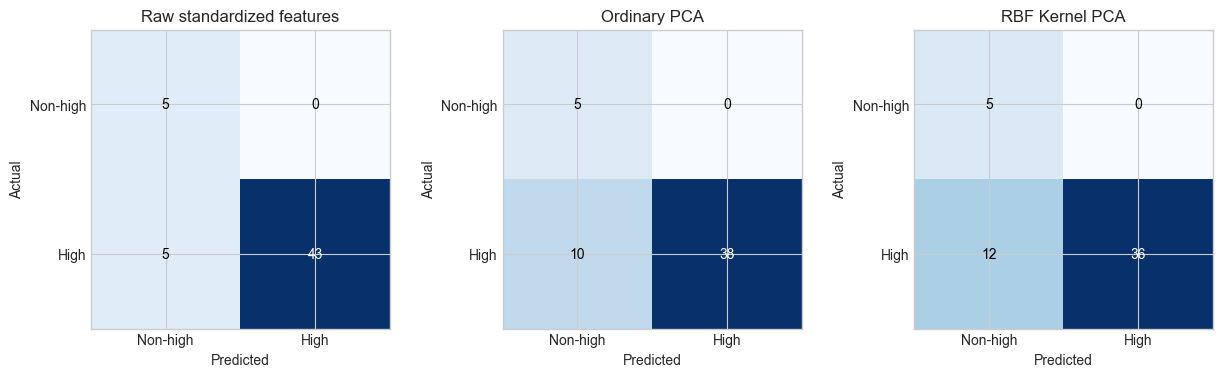

In [6]:
rows, matrices = [], {}
for name, pipeline in models.items():
    pred, probability = pipeline.predict(X_test), pipeline.predict_proba(X_test)[:, 1]
    matrices[name] = confusion_matrix(y_test, pred)
    rows.append({"Method": name, "Balanced accuracy": balanced_accuracy_score(y_test, pred),
                 "Macro F1": f1_score(y_test, pred, average="macro"),
                 "ROC AUC": roc_auc_score(y_test, probability)})
comparison = pd.DataFrame(rows).set_index("Method").sort_values("Balanced accuracy", ascending=False)
display(comparison.round(4))

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.8))
for axis, (name, matrix) in zip(axes, matrices.items()):
    axis.imshow(matrix, cmap="Blues")
    for row in range(2):
        for column in range(2):
            axis.text(column, row, matrix[row, column], ha="center", va="center",
                color="white" if matrix[row, column] > matrix.max() / 2 else "black")
    axis.set(title=name, xlabel="Predicted", ylabel="Actual")
    axis.set_xticks([0, 1], ["Non-high", "High"])
    axis.set_yticks([0, 1], ["Non-high", "High"])
plt.tight_layout()
plt.savefig(FIGURE_DIR / "q12_world_bank_confusion_matrices.png", dpi=180, bbox_inches="tight")
plt.show()

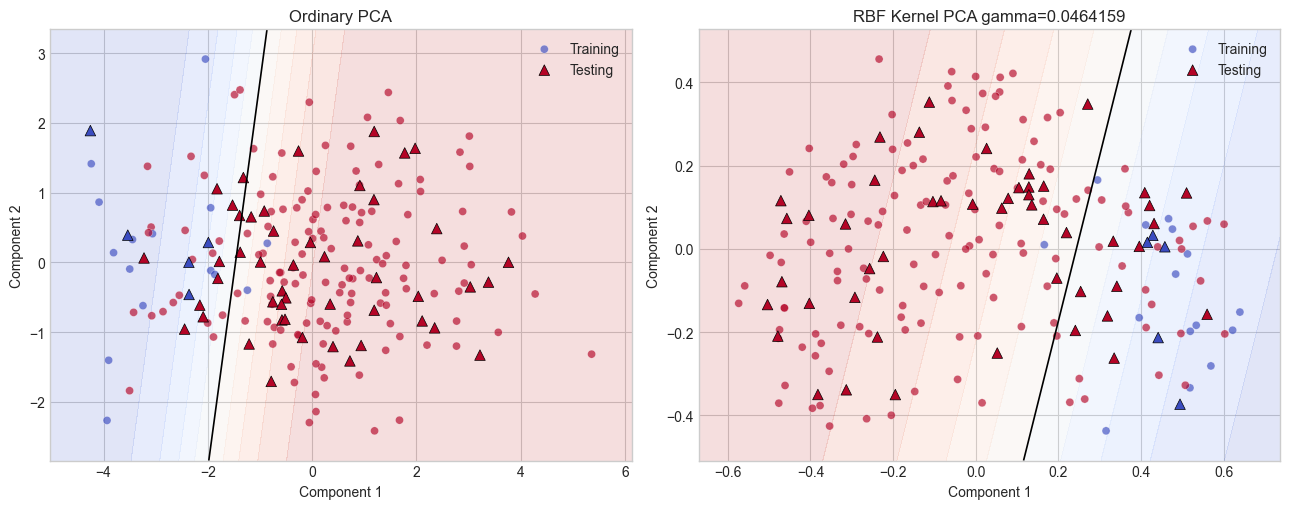

In [7]:
def transform(pipeline, values):
    values = pipeline.named_steps["impute"].transform(values)
    values = pipeline.named_steps["scale"].transform(values)
    return pipeline.named_steps["reduce"].transform(values)

representations = {
    "Ordinary PCA": (transform(pca_pipeline, X_train), transform(pca_pipeline, X_test), pca_pipeline),
    f"RBF Kernel PCA gamma={best_gamma:g}": (
        transform(search.best_estimator_, X_train), transform(search.best_estimator_, X_test), search.best_estimator_),
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for axis, (title, (train_values, test_values, pipeline)) in zip(axes, representations.items()):
    all_values = np.vstack([train_values, test_values])
    padding = 0.08 * np.maximum(np.ptp(all_values, axis=0), 1e-6)
    xx, yy = np.meshgrid(
        np.linspace(all_values[:, 0].min()-padding[0], all_values[:, 0].max()+padding[0], 220),
        np.linspace(all_values[:, 1].min()-padding[1], all_values[:, 1].max()+padding[1], 220))
    probability = pipeline.named_steps["classifier"].predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1].reshape(xx.shape)
    axis.contourf(xx, yy, probability, levels=np.linspace(0, 1, 11), cmap="coolwarm", alpha=0.16)
    axis.contour(xx, yy, probability, levels=[0.5], colors="black", linewidths=1.2)
    axis.scatter(train_values[:, 0], train_values[:, 1], c=y_train, cmap="coolwarm",
                 s=34, alpha=0.65, edgecolor="white", linewidth=0.3, label="Training")
    axis.scatter(test_values[:, 0], test_values[:, 1], c=y_test, cmap="coolwarm",
                 s=58, marker="^", edgecolor="black", linewidth=0.5, label="Testing")
    axis.set(title=title, xlabel="Component 1", ylabel="Component 2")
    axis.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "q12_world_bank_embeddings_boundaries.png", dpi=180, bbox_inches="tight")
plt.show()

,Gamma,Mean train balanced accuracy,Mean CV balanced accuracy,CV standard deviation
0,0.0010,0.8668,0.8556,0.0896
1,0.0022,0.8668,0.8556,0.0896
2,0.0046,0.8642,0.8556,0.0896
3,0.0100,0.8791,0.8521,0.0854
4,0.0215,0.8756,0.8818,0.0816
5,0.0464,0.8703,0.8854,0.0748
6,0.1000,0.8628,0.8521,0.0765
7,0.2154,0.8632,0.8415,0.0838
8,0.4642,0.7444,0.7483,0.1550
9,1.0000,0.6023,0.5392,0.1096


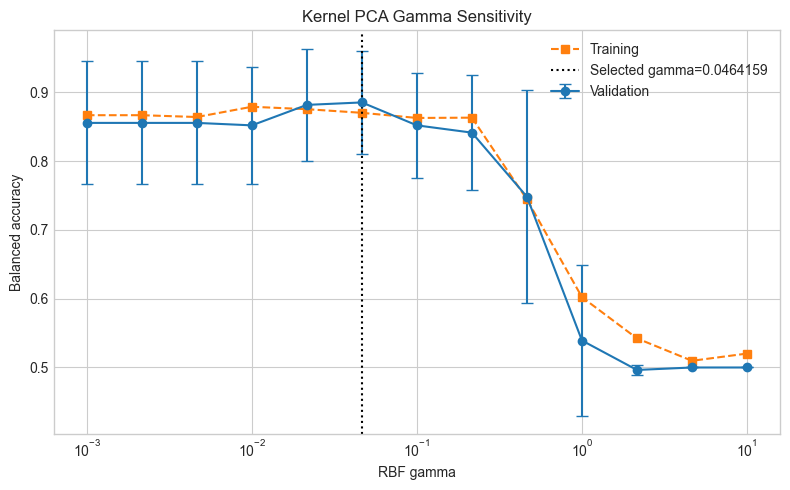

In [8]:
cv_results = pd.DataFrame(search.cv_results_)
sensitivity = cv_results[["param_reduce__gamma", "mean_train_score", "mean_test_score", "std_test_score"]].rename(columns={
    "param_reduce__gamma": "Gamma", "mean_train_score": "Mean train balanced accuracy",
    "mean_test_score": "Mean CV balanced accuracy", "std_test_score": "CV standard deviation",
}).sort_values("Gamma")
display(sensitivity.round(4))

plt.figure(figsize=(8, 5))
plt.errorbar(sensitivity.Gamma, sensitivity["Mean CV balanced accuracy"],
             yerr=sensitivity["CV standard deviation"], marker="o", capsize=4, label="Validation")
plt.plot(sensitivity.Gamma, sensitivity["Mean train balanced accuracy"], marker="s", linestyle="--", label="Training")
plt.axvline(best_gamma, color="black", linestyle=":", label=f"Selected gamma={best_gamma:g}")
plt.xscale("log")
plt.xlabel("RBF gamma")
plt.ylabel("Balanced accuracy")
plt.title("Kernel PCA Gamma Sensitivity")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "q12_world_bank_gamma_sensitivity.png", dpi=180, bbox_inches="tight")
plt.show()

In [9]:
artifact = {"dataset": "World Bank World Development Indicators cross-section",
    "year": selected_year, "economies": len(data), "selected_gamma": best_gamma,
    "best_cv_balanced_accuracy": float(search.best_score_),
    "test_metrics": {name: {metric: float(value) for metric, value in row.items()}
                     for name, row in comparison.iterrows()},
    "confusion_matrices": {name: matrix.tolist() for name, matrix in matrices.items()}}
metric_path = METRIC_DIR / "q12_kernel_pca_world_bank.json"
metric_path.write_text(json.dumps(artifact, indent=2) + "\n")

pca_score = comparison.loc["Ordinary PCA", "Balanced accuracy"]
kpca_score = comparison.loc["RBF Kernel PCA", "Balanced accuracy"]
raw_score = comparison.loc["Raw standardized features", "Balanced accuracy"]
difference = kpca_score - pca_score
finding = "improved separation relative to ordinary PCA" if difference > 0.01 else (
    "performed worse than ordinary PCA" if difference < -0.01 else "performed similarly to ordinary PCA")
print(f"Conclusion: On held-out {selected_year} economies, RBF Kernel PCA {finding}. "
      f"Its balanced accuracy was {kpca_score:.3f}, versus {pca_score:.3f} for ordinary PCA. "
      f"The unreduced nine-feature baseline scored {raw_score:.3f}, showing the predictive information "
      "lost when either method compresses the data to only two dimensions. "
      f"Gamma={best_gamma:g} was selected only from training folds. This result is specific to this "
      "cross-section and does not imply causation or universal nonlinear income-group structure.")
print("Saved", metric_path.relative_to(ROOT))

Conclusion: On held-out 2023 economies, RBF Kernel PCA performed worse than ordinary PCA. Its balanced accuracy was 0.875, versus 0.896 for ordinary PCA. The unreduced nine-feature baseline scored 0.948, showing the predictive information lost when either method compresses the data to only two dimensions. Gamma=0.0464159 was selected only from training folds. This result is specific to this cross-section and does not imply causation or universal nonlinear income-group structure.
Saved results\metrics\q12_kernel_pca_world_bank.json
